In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto sólo se conserva su programación de inicios más tempranos: la semana en que empieza cada actividad y su duración (cuadro adjunto). Se sabe que el calendario se calculó correctamente a partir de un cuadro de prelaciones que se ha perdido.

In [4]:
pregunta_1 = "1. Dibuje el diagrama de Gantt y calcule el fin más temprano de cada actividad y la duración del proyecto.  "
pregunta_2 = "2. ¿Qué actividades son iniciales? Para cada una de las demás, ¿qué actividades *pueden* ser predecesoras inmediatas suyas (terminan no más tarde de su inicio) y cuáles son las «ajustadas» (terminan exactamente cuando ella empieza)? ¿Por qué toda actividad no inicial tiene al menos una predecesora ajustada?  "
pregunta_3 = "3. Encadenando actividades ajustadas desde la semana 0 hasta el final, identifique una ruta crítica. ¿Puede haber más de una?  "
pregunta_4 = "4. Se recupera el cuadro de prelaciones original. Compruebe que es compatible con el Gantt y compare sus prelaciones con las predecesoras ajustadas deducidas.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el diagrama de Gantt y calcule el fin más temprano de cada actividad y la duración del proyecto.  

2. ¿Qué actividades son iniciales? Para cada una de las demás, ¿qué actividades *pueden* ser predecesoras inmediatas suyas (terminan no más tarde de su inicio) y cuáles son las «ajustadas» (terminan exactamente cuando ella empieza)? ¿Por qué toda actividad no inicial tiene al menos una predecesora ajustada?  

3. Encadenando actividades ajustadas desde la semana 0 hasta el final, identifique una ruta crítica. ¿Puede haber más de una?  

4. Se recupera el cuadro de prelaciones original. Compruebe que es compatible con el Gantt y compare sus prelaciones con las predecesoras ajustadas deducidas.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, start, duration
    ('A'     , 0    , 6       ),
    ('B'     , 0    , 4       ),
    ('C'     , 6    , 6       ),
    ('D'     , 12   , 2       ),
    ('E'     , 4    , 5       ),
    ('F'     , 9    , 3       ),
    ('G'     , 14   , 1       ),
], columns=['activity', 'start', 'duration']).set_index('activity')
datos_enunciado

,start,duration
activity,,
A,0,6
B,0,4
C,6,6
D,12,2
E,4,5
F,9,3
G,14,1


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal


# Resolución

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el diagrama de Gantt y calcule el fin más temprano de cada actividad y la duración del proyecto.  

In [8]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['end'] = datos_proyecto['start'] + datos_proyecto['duration']
duracion_proyecto = int(datos_proyecto['end'].max())
datos_proyecto

,start,duration,end
activity,,,
A,0,6,6
B,0,4,4
C,6,6,12
D,12,2,14
E,4,5,9
F,9,3,12
G,14,1,15


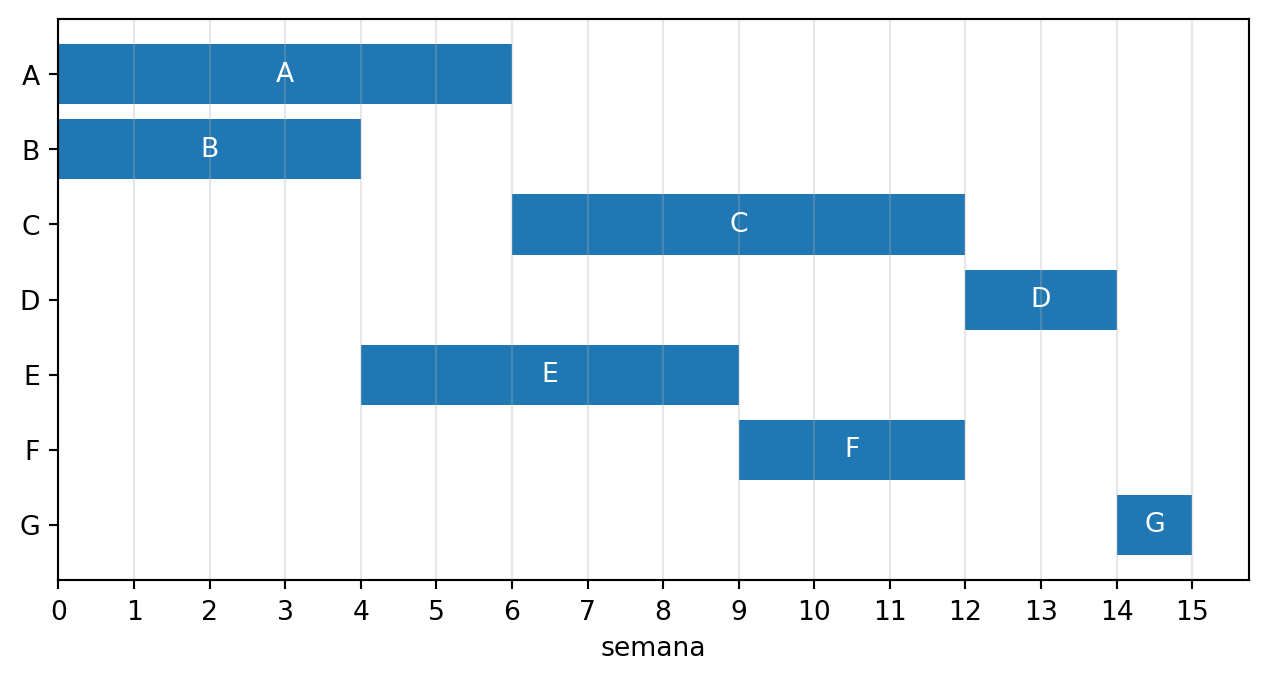

In [9]:
#| fig-cap: "Diagrama de Gantt de la programación conservada"
#| label: fig-gantt
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 0.4 * len(datos_proyecto) + 1))
for y, (a, fila) in enumerate(datos_proyecto.iterrows()):
    ax.barh(y, fila['duration'], left=fila['start'], color='tab:blue')
    ax.text(fila['start'] + fila['duration'] / 2, y, a, ha='center', va='center', color='white')
ax.set_yticks(range(len(datos_proyecto))); ax.set_yticklabels(datos_proyecto.index); ax.invert_yaxis()
ax.set_xlabel('semana'); ax.set_xticks(range(duracion_proyecto + 1)); ax.grid(axis='x', alpha=0.3)
plt.show()

In [10]:
Markdown(f'La duración del proyecto es el mayor fin: {duracion_proyecto} semanas.')

La duración del proyecto es el mayor fin: 15 semanas.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. ¿Qué actividades son iniciales? Para cada una de las demás, ¿qué actividades *pueden* ser predecesoras inmediatas suyas (terminan no más tarde de su inicio) y cuáles son las «ajustadas» (terminan exactamente cuando ella empieza)? ¿Por qué toda actividad no inicial tiene al menos una predecesora ajustada?  

Una actividad que empieza en la semana 0 es inicial. Si $P$ terminara después de que empiece $A$, $P$ no podría ser predecesora de $A$. En un calendario de inicios más tempranos, el inicio de cada actividad no inicial es el *máximo* de los fines de sus predecesoras, luego alguna de ellas termina exactamente cuando la actividad empieza.

In [12]:
posibles, ajustadas = {}, {}
for a, fila in datos_proyecto.iterrows():
    posibles[a] = sorted(p for p, f in datos_proyecto.iterrows() if p != a and f['end'] <= fila['start'])
    ajustadas[a] = sorted(p for p in posibles[a] if datos_proyecto.loc[p, 'end'] == fila['start'])
iniciales = datos_proyecto.index[datos_proyecto['start'] == 0].tolist()
print('Iniciales:', ', '.join(iniciales))
pd.DataFrame({'posibles predecesoras': {a: ', '.join(v) or '—' for a, v in posibles.items()},
              'ajustadas (fin = inicio)': {a: ', '.join(v) or '—' for a, v in ajustadas.items()}})

Iniciales: A, B


,posibles predecesoras,ajustadas (fin = inicio)
A,—,—
B,—,—
C,"A, B",A
D,"A, B, C, E, F","C, F"
E,B,B
F,"A, B, E",E
G,"A, B, C, D, E, F",D


## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Encadenando actividades ajustadas desde la semana 0 hasta el final, identifique una ruta crítica. ¿Puede haber más de una?  

In [14]:
finales = datos_proyecto.index[datos_proyecto['end'] == duracion_proyecto].tolist()
def cadenas(a):
    if datos_proyecto.loc[a, 'start'] == 0:
        return [[a]]
    return [c + [a] for p in ajustadas[a] for c in cadenas(p)]
rutas_criticas_deducidas = [c for f in finales for c in cadenas(f)]
for c in rutas_criticas_deducidas:
    print(' - '.join(c), '=', ' + '.join(str(int(datos_proyecto.loc[x, 'duration'])) for x in c), '=', duracion_proyecto)
Markdown(f'Se deducen {len(rutas_criticas_deducidas)} cadena(s) ajustada(s) de la semana 0 al final: cada una es una ruta crítica '
         '*si* todas sus prelaciones consecutivas existen en el cuadro perdido; puede haber más de una.')

A - C - D - G = 6 + 6 + 2 + 1 = 15
B - E - F - D - G = 4 + 5 + 3 + 2 + 1 = 15


Se deducen 2 cadena(s) ajustada(s) de la semana 0 al final: cada una es una ruta crítica *si* todas sus prelaciones consecutivas existen en el cuadro perdido; puede haber más de una.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Se recupera el cuadro de prelaciones original. Compruebe que es compatible con el Gantt y compare sus prelaciones con las predecesoras ajustadas deducidas.  

In [16]:
#| tbl-cap: "Cuadro de prelaciones recuperado"
#| label: tbl-prelacionesRecuperado
prelaciones_recuperadas = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 6       ),
    ('B'     , '---'      , 4       ),
    ('C'     , 'A,B'      , 6       ),
    ('D'     , 'C'        , 2       ),
    ('E'     , 'B'        , 5       ),
    ('F'     , 'E'        , 3       ),
    ('G'     , 'D,F'      , 1       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
prelaciones_recuperadas

,predecessor,duration
activity,,
A,---,6
B,---,4
C,"A,B",6
D,C,2
E,B,5
F,E,3
G,"D,F",1


In [17]:
prelaciones = PredecessorTable.from_dataframe_of_strings(prelaciones_recuperadas, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(prelaciones_recuperadas['duration'])
compatible = (calendario['inicio_mas_temprano'] == datos_proyecto['start']).all()
comparacion = pd.DataFrame({'predecesoras reales': {a: ', '.join(sorted(ps)) or '—' for a, ps in prelaciones.immediate_predecessor.items()},
                            'ajustadas deducidas': {a: ', '.join(v) or '—' for a, v in ajustadas.items()}})
G = nx.DiGraph([(p, a) for a, ps in prelaciones.immediate_predecessor.items() for p in ps]); G.add_nodes_from(comparacion.index)
comparacion['ajustadas que son antecesoras'] = [', '.join(sorted(set(ajustadas[a]) & nx.ancestors(G, a))) or '—' for a in comparacion.index]
comparacion['ajustadas por coincidencia'] = [', '.join(sorted(set(ajustadas[a]) - nx.ancestors(G, a))) or '—' for a in comparacion.index]
display(comparacion)
Markdown(f'El cuadro recuperado reproduce el Gantt: {compatible}. Una predecesora ajustada suele ser una antecesora real (inmediata o no), '
         'pero puede ser una coincidencia de fechas; y las predecesoras reales con holgura entre su fin y el inicio de la sucesora no se ven en el Gantt. '
         'Por eso el Gantt no determina el cuadro de prelaciones.')

,predecesoras reales,ajustadas deducidas,ajustadas que son antecesoras,ajustadas por coincidencia
A,—,—,—,—
B,—,—,—,—
C,"A, B",A,A,—
D,C,"C, F",C,F
E,B,B,B,—
F,E,E,E,—
G,"D, F",D,D,—


El cuadro recuperado reproduce el Gantt: True. Una predecesora ajustada suele ser una antecesora real (inmediata o no), pero puede ser una coincidencia de fechas; y las predecesoras reales con holgura entre su fin y el inicio de la sucesora no se ven en el Gantt. Por eso el Gantt no determina el cuadro de prelaciones.

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

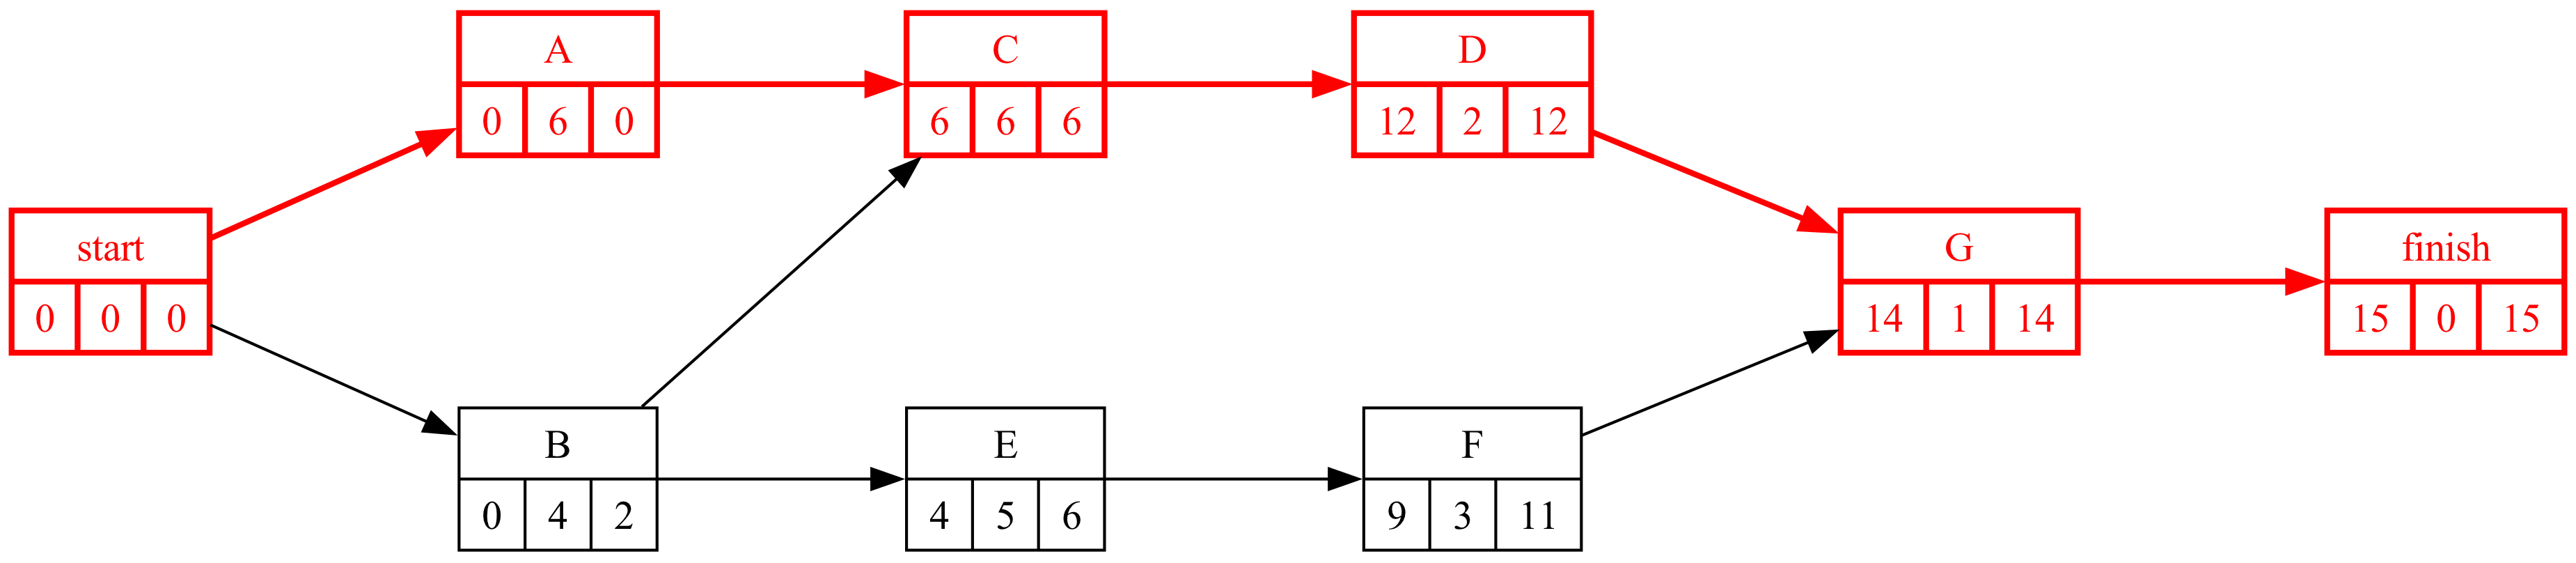

In [18]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-pert
proyecto.display_roy_pasos(prelaciones_recuperadas['duration'])